# 09 Regularized logistic regression on the improved features

Follow-up to notebook 04 (regularized logistic regression, F1 = 0.423 on an 80/20 split). Notebooks 06-08 found
that the biggest gains come from the **features**, not the model: with the feature set of notebook 07, least
squares reaches 0.431 in cross-validation and **0.442 on AIcrowd**. This notebook gives logistic regression the
same features.

Two differences from notebook 04:

1. **Features**: built from the raw CSVs by `feature_engineering.py` (notebook 01's cleaning, plus three feature
   groups notebook 01 drops, squares of numeric columns, interactions with age and sex): 1236 columns instead of 281.
2. **Solver**: `fe.reg_logistic_newton` minimizes **the same objective** as `reg_logistic_regression` from
   `implementations.py` (mean logistic loss + λ‖w‖²), but with Newton's method: it converges in about 10 steps,
   with no step size or number of iterations to tune (section 1 checks this against the GD implementation).

Evaluation: stratified 5-fold cross-validation with an F1-tuned threshold, as in notebooks 05-08, so the numbers
are directly comparable (they are *not* directly comparable with the single 80/20 split of notebook 04).
Run time: about 15 minutes.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "implementations.py").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import feature_engineering as fe
import implementations as impl
from cross_validation import build_k_indices, cross_validation
from helpers import create_csv_submission

warnings.filterwarnings("ignore", message=".*encountered in matmul")

K_FOLD = 5
SEED = 1
GROUPS = ("redundant", "risk_management", "optional_modules")   # same features as notebooks 07 and 08
INTERACT = ("_AGE80", "SEX=2")

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2, "font.size": 10,
})

In [2]:
start = time.time()
raw = fe.load_raw(PROJECT_ROOT / "dataset")
decoded = fe.decode_missing(raw)
y = raw["y_train"]
k_indices = build_k_indices(y, K_FOLD, seed=SEED)

x_tr, x_te, names = fe.build_features(raw, keep_groups=GROUPS, decoded=decoded,
                                      square_numeric=True, interact_with=INTERACT)
tx = np.c_[np.ones(len(x_tr)), x_tr]
tx_test = np.c_[np.ones(len(x_te)), x_te]
del x_tr, x_te
print(f"train: {tx.shape}, test: {tx_test.shape}, positives: {y.mean():.2%}  ({time.time() - start:.0f}s)")

train: (328135, 1236), test: (109379, 1236), positives: 8.83%  (8s)


## 1. Newton vs gradient descent on the same objective

Gradient descent is only stable for γ < 8/L (L = largest eigenvalue of XᵀX / N), and with these features the
problem is badly conditioned, so GD moves very slowly along some directions. Newton's method rescales every
direction with the Hessian. We train both on all rows with λ = 1e-4 and compare the objective they reach.

Newton: 8 steps, objective = 0.217964  (18s)
L = 69.4, GD step size gamma = 4/L = 0.0576
GD (600 iterations): objective = 0.222946  (49s)


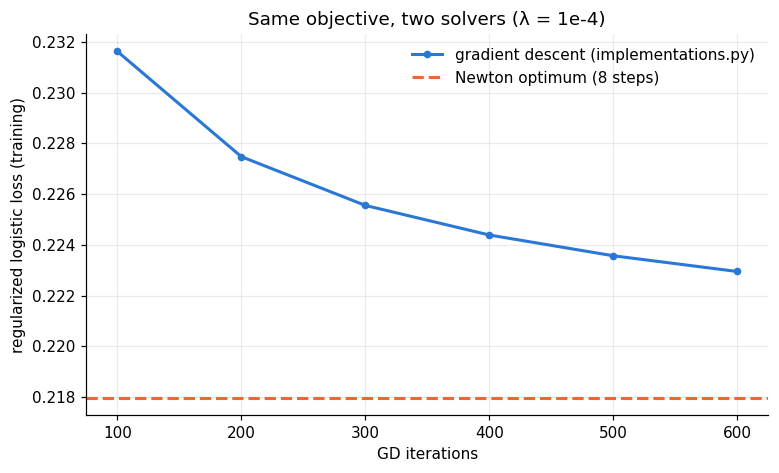

In [3]:
lam = 1e-4


def objective(w):
    z = tx @ w
    return np.mean(np.logaddexp(0, z) - y * z) + lam * w @ w


start = time.time()
w_newton, n_steps = fe.reg_logistic_newton(y, tx, lam)
print(f"Newton: {n_steps} steps, objective = {objective(w_newton):.6f}  ({time.time() - start:.0f}s)")

eigenvalues = np.linalg.eigvalsh(tx.T @ tx / len(y))
L = eigenvalues[-1]
gamma = 4 / L   # half of the stability limit 8/L
print(f"L = {L:.1f}, GD step size gamma = 4/L = {gamma:.4f}")

w = np.zeros(tx.shape[1])
gd_iters, gd_objective = [], []
start = time.time()
for _ in range(6):
    w, _ = impl.reg_logistic_regression(y, tx, lam, w, 100, gamma)   # continue from w
    gd_iters.append(100 * (len(gd_iters) + 1))
    gd_objective.append(objective(w))
print(f"GD ({gd_iters[-1]} iterations): objective = {gd_objective[-1]:.6f}  ({time.time() - start:.0f}s)")

fig, ax = plt.subplots()
ax.plot(gd_iters, gd_objective, color=BLUE, marker="o", markersize=4, label="gradient descent (implementations.py)")
ax.axhline(objective(w_newton), color=ORANGE, linestyle="--", label=f"Newton optimum ({n_steps} steps)")
ax.set_xlabel("GD iterations")
ax.set_ylabel("regularized logistic loss (training)")
ax.set_title("Same objective, two solvers (λ = 1e-4)")
ax.legend(frameon=False)
plt.show()

## 2. Grid search: λ and class weight

`pos_weight` = how many times each positive row counts in the loss (1 = plain logistic regression). For logistic
regression this mostly shifts the intercept, which the tuned threshold already does, so we expect it to matter less
than for least squares (notebook 08).

In [4]:
def newton(y, tx, params):
    return fe.reg_logistic_newton(y, tx, params["lambda_"], pos_weight=params["pos_weight"])[0]


grid = {}
for lam in [1e-5, 1e-4, 1e-3]:
    for pos_weight in [1.0, 2.0]:
        start = time.time()
        r = cross_validation(y, tx, newton, {"lambda_": lam, "pos_weight": pos_weight}, k_indices)
        grid[(lam, pos_weight)] = r
        print(f"λ = {lam:<6g} pos_weight = {pos_weight:g}   F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   "
              f"P = {r['precision_mean']:.3f}  R = {r['recall_mean']:.3f}   ({time.time() - start:.0f}s)")

BEST_LAMBDA, BEST_POS_WEIGHT = max(grid, key=lambda key: grid[key]["f1_mean"])
best_cv = grid[(BEST_LAMBDA, BEST_POS_WEIGHT)]
print(f"\nbest: λ = {BEST_LAMBDA:g}, pos_weight = {BEST_POS_WEIGHT:g}, "
      f"F1 = {best_cv['f1_mean']:.4f} ± {best_cv['f1_std']:.4f}, threshold on tx @ w = {best_cv['threshold']:.4f}")

λ = 1e-05  pos_weight = 1   F1 = 0.4315 ± 0.0055   P = 0.351  R = 0.560   (76s)
λ = 1e-05  pos_weight = 2   F1 = 0.4316 ± 0.0052   P = 0.353  R = 0.556   (67s)
λ = 0.0001 pos_weight = 1   F1 = 0.4323 ± 0.0043   P = 0.364  R = 0.533   (76s)
λ = 0.0001 pos_weight = 2   F1 = 0.4325 ± 0.0043   P = 0.362  R = 0.536   (69s)
λ = 0.001  pos_weight = 1   F1 = 0.4320 ± 0.0047   P = 0.364  R = 0.532   (80s)
λ = 0.001  pos_weight = 2   F1 = 0.4326 ± 0.0046   P = 0.361  R = 0.541   (73s)

best: λ = 0.001, pos_weight = 2, F1 = 0.4326 ± 0.0046, threshold on tx @ w = -0.6323


## 3. Comparison with the other models

Cross-validated F1 of the other notebooks, all with the same 5 stratified folds:

| Model | Features | CV F1 | AIcrowd |
|---|---|---|---|
| Reg. logistic regression, GD (nb 05) | notebook 01 + squares | ~0.418 | |
| Ridge (nb 05) | notebook 01 | 0.412 | |
| Ridge, undersample 1:5 (nb 07) | notebook 07 | 0.4317 | 0.441 |
| Weighted least squares, c = 3 (nb 08) | notebook 07 | 0.4314 | 0.442 |

All linear models on these features land between 0.431 and 0.433: the remaining gap to the best leaderboard
scores is not about which loss is minimized.

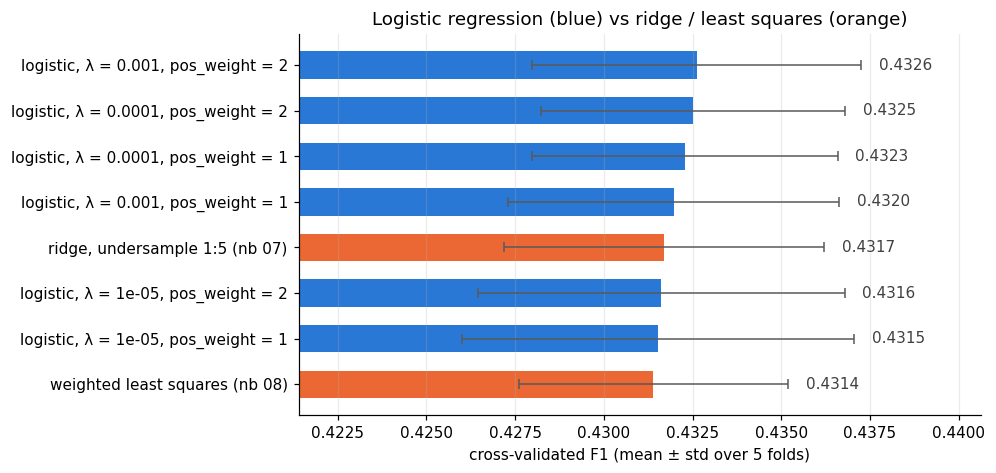

In [5]:
references = {
    "ridge, undersample 1:5 (nb 07)": (0.4317, 0.0045),
    "weighted least squares (nb 08)": (0.4314, 0.0038),
}
rows = [(f"logistic, λ = {lam:g}, pos_weight = {pw:g}", r["f1_mean"], r["f1_std"], BLUE)
        for (lam, pw), r in grid.items()]
rows += [(name, m, s, ORANGE) for name, (m, s) in references.items()]
rows.sort(key=lambda row: row[1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([r[0] for r in rows], [r[1] for r in rows], xerr=[r[2] for r in rows], color=[r[3] for r in rows],
        height=0.6, error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
for i, r in enumerate(rows):
    ax.text(r[1] + r[2] + 0.0005, i, f"{r[1]:.4f}", va="center", color="0.25")
ax.set_xlim(min(r[1] for r in rows) - 0.01, max(r[1] for r in rows) + 0.008)
ax.set_xlabel("cross-validated F1 (mean ± std over 5 folds)")
ax.set_title("Logistic regression (blue) vs ridge / least squares (orange)")
ax.grid(axis="y", visible=False)
plt.show()

## 4. Final model and submission

Retrained on all training rows with the best (λ, pos_weight); the threshold on the score `tx @ w` is the one
chosen by cross-validation (thresholding the score is the same as thresholding the probability `sigmoid(tx @ w)`).

In [6]:
w_final, n_steps = fe.reg_logistic_newton(y, tx, BEST_LAMBDA, pos_weight=BEST_POS_WEIGHT)
threshold = best_cv["threshold"]
print(f"trained on {len(y)} rows in {n_steps} Newton steps; threshold: score {threshold:.4f} "
      f"= probability {impl.sigmoid(threshold):.4f}")

test_predictions = np.where(tx_test @ w_final >= threshold, 1, -1)
oof_rate = np.mean(best_cv["oof_scores"] >= threshold)
print(f"predicted positive rate: test {np.mean(test_predictions == 1):.4f}, out-of-fold {oof_rate:.4f}")

submission_path = PROJECT_ROOT / "submission_logistic_best.csv"
create_csv_submission(raw["test_ids"], test_predictions, submission_path)
print(f"submission written to {submission_path}")

trained on 328135 rows in 7 Newton steps; threshold: score -0.6323 = probability 0.3470
predicted positive rate: test 0.1331, out-of-fold 0.1325
submission written to /Users/ema/Desktop/EPFL/Machine Learning/ML_Project1/submission_logistic_best.csv


## 5. Conclusions

CONCLUSIONS_PLACEHOLDER